# M1.5 · 高频数据与另类数据

> 高频数据和另类数据是超额收益的前沿来源，也带来数据清洗、工程性能和信号稀疏性的挑战。
> 本节理解高频数据特点与清洗、高频策略类型、另类数据类别与使用陷阱、高频工程挑战。

## 一、高频数据的特点

- 频率高：tick（逐笔成交/挂单）、秒、分钟，数据量远大于日频；
- 噪声大、非同步、不规则时间间隔；
- 信息更及时但信号衰减快，对延迟和执行敏感；
- 包含订单簿、成交方向、挂撤单等微观信息。

## 二、高频数据清洗

- 时间戳统一、跨市场时钟对齐；
- 异常 tick（错误价格、闪崩、数据重复）识别与剔除；
- 停牌、涨跌停、集合竞价特殊处理；
- 不规则 tick 聚合为规则 bar（OHLCV）。

In [1]:
# 演示：不规则 tick 聚合为 5 分钟 bar（教学版）
import numpy as np, pandas as pd
rng = np.random.default_rng(7)
# 生成带随机时间间隔的 tick
times = pd.date_range('2026-01-05 09:30', periods=200, freq='30s')
price = 10 + np.cumsum(rng.normal(0, 0.01, 200))
qty = rng.integers(100, 1000, 200)
ticks = pd.DataFrame({'price': price, 'qty': qty}, index=times)
# 聚合为5分钟 OHLCV
bars = ticks.resample('5min').agg(
    open=('price', 'first'), high=('price', 'max'),
    low=('price', 'min'), close=('price', 'last'),
    volume=('qty', 'sum')).dropna()
print('tick 数:', len(ticks), ' 5分钟bar 数:', len(bars))
bars.head(4)

tick 数: 200  5分钟bar 数: 20


,open,high,low,close,volume
2026-01-05 09:30:00,10.000012,10.003000,9.976889,9.979766,5179
2026-01-05 09:35:00,9.984664,9.989287,9.936717,9.936717,4742
2026-01-05 09:40:00,9.918300,9.918300,9.874646,9.875779,5699
2026-01-05 09:45:00,9.860478,9.860478,9.837827,9.841926,5961


## 三、高频策略类型

| 策略 | 核心逻辑 |
|---|---|
| 做市（market making） | 双边挂单赚价差，管理库存和逆向选择 |
| 统计套利 | 价差/协整关系的短期偏离回归 |
| 订单流策略 | 利用 OFI、VPIN、大单/挂单失衡预测短期方向 |
| 高频动量/反转 | 极短期价格延续或反转 |
| 执行算法 | TWAP/VWAP/POV 降低冲击（L1 已学） |

> 高频靠"薄利多销、积少成多"，对成本、延迟、容量极敏感。

## 四、另类数据

- 舆情/社交媒体情绪、新闻文本；
- 分析师研报、盈利预测、电话会议；
- 资金流向、龙虎榜、北向资金、融资融券；
- 供应链、卫星图像、地理位置、招聘、ESG 等。

**使用要点：**
- 另类数据价值在于"信息增量"，要检验是否带来超额、是否已被定价；
- 陷阱：样本短、覆盖偏差、噪声大、前视偏差（发布时间）、过拟合；
- 文本类需 NLP 处理，非结构化数据工程量大。

In [2]:
# 简单情绪因子示例：用模拟情绪分数预测短期方向（方法演示）
sentiment = rng.normal(0, 1, len(bars))
fwd_ret = bars['close'].pct_change().shift(-1)
dfa = pd.DataFrame({'sentiment': sentiment, 'fwd_ret': fwd_ret.values}).dropna()
ic = dfa['sentiment'].corr(dfa['fwd_ret'], method='spearman')
print('模拟情绪因子短期 RankIC = %.4f（真实数据需重新检验，注意样本与发布时间）' % ic)

模拟情绪因子短期 RankIC = -0.3789（真实数据需重新检验，注意样本与发布时间）


## 五、高频工程挑战

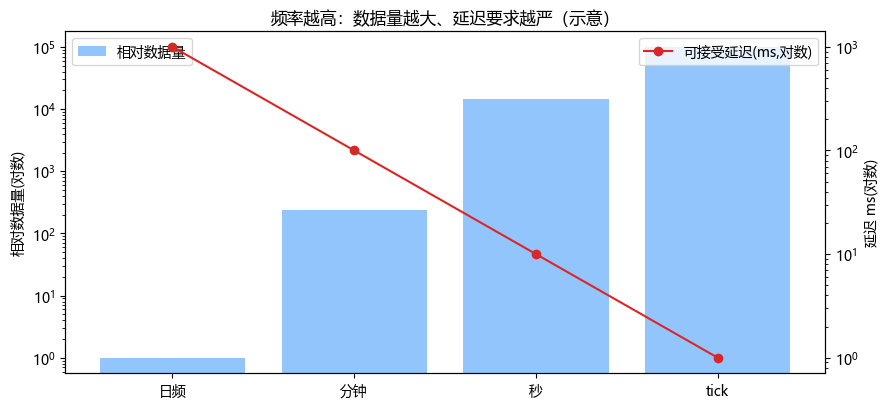

In [3]:
import matplotlib.pyplot as plt
plt.rcParams['font.sans-serif'] = ['Microsoft YaHei']
plt.rcParams['axes.unicode_minus'] = False
fig, ax = plt.subplots(figsize=(9, 4.2))
# 不同频率的相对数据量与延迟要求（示意，非精确值）
labels = ['日频', '分钟', '秒', 'tick']
data_vol = [1, 240, 14400, 100000]
latency = [1000, 100, 10, 1]
ax2 = ax.twinx()
ax.bar(np.arange(4), data_vol, color='#93c5fd', label='相对数据量')
ax2.plot(np.arange(4), latency, 'o-', color='#dc2626', label='可接受延迟(ms,对数)')
ax2.set_yscale('log'); ax.set_yscale('log')
ax.set_xticks(np.arange(4)); ax.set_xticklabels(labels)
ax.set_ylabel('相对数据量(对数)'); ax2.set_ylabel('延迟 ms(对数)')
ax.set_title('频率越高：数据量越大、延迟要求越严（示意）')
ax.legend(loc='upper left'); ax2.legend(loc='upper right')
plt.tight_layout(); plt.show()

- 低延迟：网络、代码、硬件协同优化（共址、内核旁路、C++/高效语言）；
- 高吞吐：消息队列、流式处理、内存计算；
- 存储：时序/列存数据库，高写入与快速回放；
- 可靠性：监控、容灾、幂等、断线重连。

## 六、小结与面试要点

- 高频数据量大、噪声大、衰减快，需清洗并聚合为规则 bar；策略含做市、统计套利、订单流等。
- 另类数据提供信息增量，但要防样本短、覆盖偏差、前视和过拟合。
- 高频工程核心是低延迟、高吞吐、可靠存储与运维。

**面试高频：**
- 高频数据怎么清洗？（答：时间戳对齐、异常剔除、停牌处理、聚合bar）
- 做市策略怎么赚钱、风险是什么？（答：赚价差，风险是库存和逆向选择）
- 另类数据使用要注意什么？（答：信息增量、发布时间防前视、覆盖偏差、过拟合）
- 为什么高频对延迟敏感？（答：信号衰减快，慢一步就抢不到价格/成交）

## 动手练习
1. 把一段 tick 数据聚合为不同周期的 bar 并比较；
2. 选一类另类数据，写出从获取到因子检验的完整流程；
3. 列出高频系统在延迟、吞吐、存储上的具体优化手段。

---
**M1（数据与微观结构）五个 notebook 全部完成。** 下一阶段进入 B2（M2 因子进阶）。